# Plot microscopic cross sections for nuclides and reactions of interest

<!-- index:description -->
Plot and overlay microscopic neutron cross sections for selected nuclides and reactions relevant to tritium breeding and blanket neutronics in fusion reactors.
<!-- /index:description -->

<!-- generated:structure -->
```text
Plot microscopic cross sections for nuclides and reactions of interest
```
<!-- /generated:structure -->


In [1]:
import openmc
import pandas as pd
import matplotlib.pyplot as plt

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

pairs = pd.DataFrame([
    ('Li6',  'Li7',   '(n,Xt)'),
    ('Be9',  'Pb208', '(n,2n)'),
    ('B10',  'B11',   '(n,a)'),
    ('H1',   'H2',    'elastic'),
    ('Fe56', 'W184',  '(n,2n)'),
    ('Fe56', 'W184',  '(n,gamma)'),
    ('F19',  'O16',   '(n,p)'),
    ('F19',  'O16',   '(n,a)'),
], columns=['nuclide1', 'nuclide2', 'reaction'])
pairs

,nuclide1,nuclide2,reaction
0,Li6,Li7,"(n,Xt)"
1,Be9,Pb208,"(n,2n)"
2,B10,B11,"(n,a)"
3,H1,H2,elastic
4,Fe56,W184,"(n,2n)"
5,Fe56,W184,"(n,gamma)"
6,F19,O16,"(n,p)"
7,F19,O16,"(n,a)"


In [2]:
def format_ax(ax):
    ax.grid()
    ax.set(
        xscale='log',
        yscale='log',
        xlabel='Energy (MeV)',
        ylabel='Microscopic cross section (b)',
    )
    ax.legend(loc='lower left')

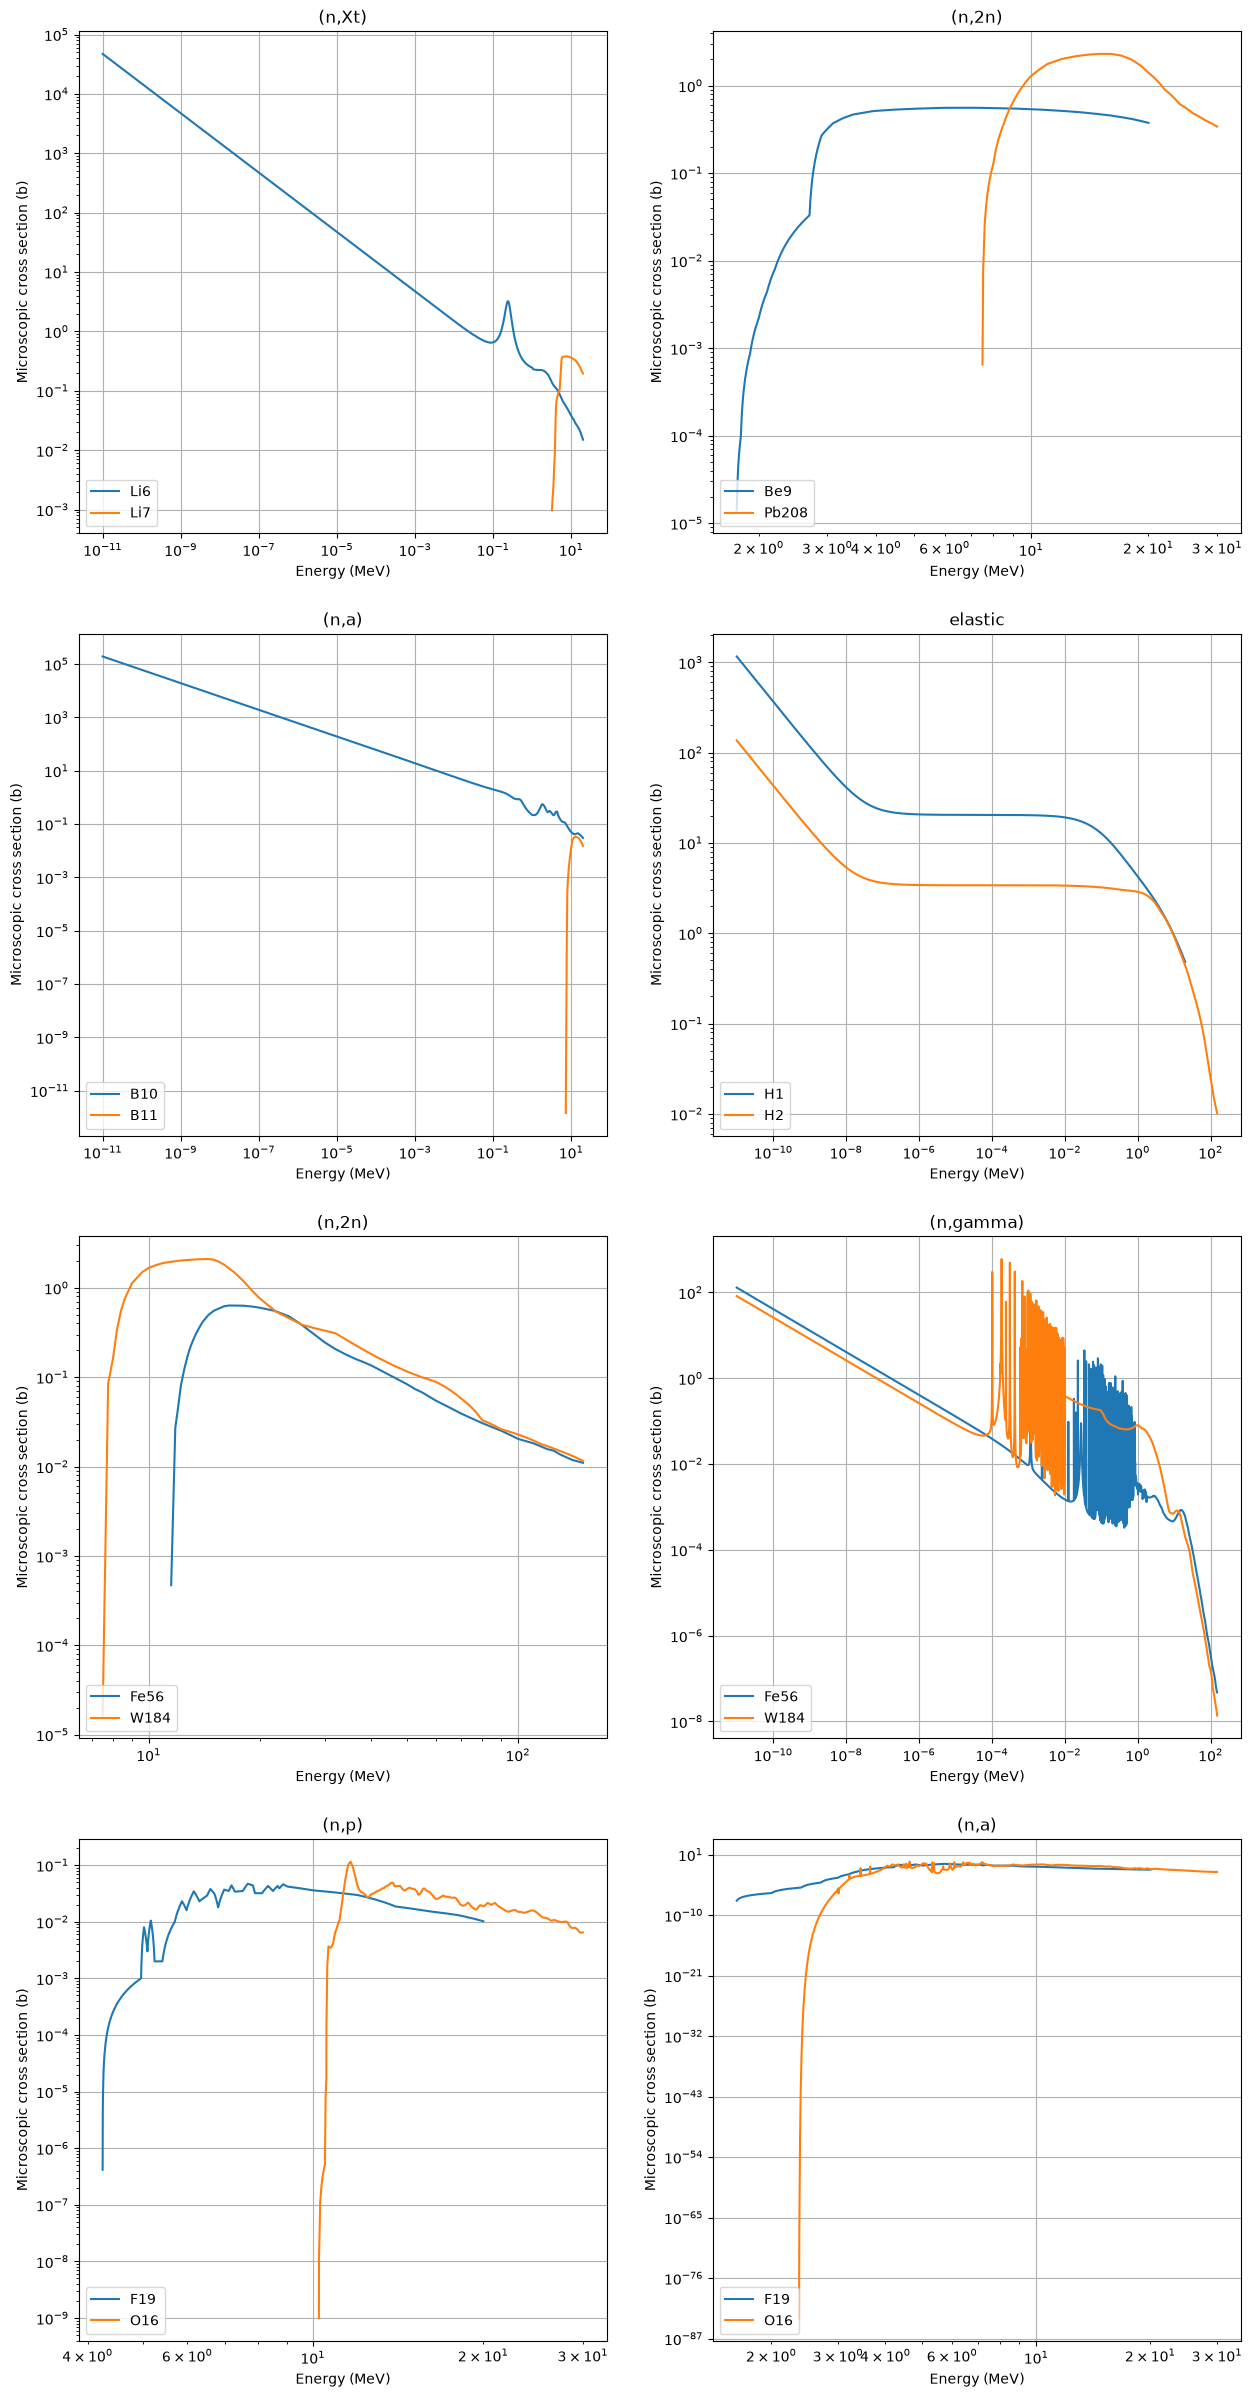

In [3]:
fig, ax = plt.subplots(4, 2, figsize=(15, 30))
ax = ax.flatten()
for nax, (nuc1, nuc2, reaction) in enumerate(pairs.itertuples(index=False, name=None)):
    for nuc in [nuc1, nuc2]:
        E, xs = openmc.plotter.calculate_cexs(
            nuc, [reaction],
        )
        xs = xs.squeeze()
        pic = xs > 0
        ax[nax].plot(E[pic] / 1e6, xs[pic], label=nuc)
    ax[nax].set_title(reaction)
    format_ax(ax[nax])